In [ ]:
df.shape

(158688, 621)

In [64]:
import pandas as pd
df = pd.read_csv(r'C:\Users\Sahitya A\Downloads\merged_healthcare_data.csv')
df.head()

KeyboardInterrupt: 

In [ ]:
df.columns

Index(['pn', 'year', 'ccr_wtd', 'ccr_min', 'ccr_max', 'beds_adultped_wtd',
       'beds_adultped_min', 'beds_adultped_max', 'beds_totadultped_wtd',
       'beds_totadultped_min',
       ...
       'copd_readm_npatients', 'copd_readm_rate', 'stk_mort_npatients',
       'stk_mort_rate', 'stk_readm_npatients', 'stk_readm_rate',
       'cabg_mort_npatients', 'cabg_mort_rate', 'cabg_readm_npatients',
       'cabg_readm_rate'],
      dtype='object', length=621)

In [ ]:
print(df.columns.tolist())

['pn', 'year', 'ccr_wtd', 'ccr_min', 'ccr_max', 'beds_adultped_wtd', 'beds_adultped_min', 'beds_adultped_max', 'beds_totadultped_wtd', 'beds_totadultped_min', 'beds_totadultped_max', 'icu_beds_wtd', 'icu_beds_min', 'icu_beds_max', 'ccu_beds_wtd', 'ccu_beds_min', 'ccu_beds_max', 'bicu_beds_wtd', 'bicu_beds_min', 'bicu_beds_max', 'sicu_beds_wtd', 'sicu_beds_min', 'sicu_beds_max', 'othspec_beds_wtd', 'othspec_beds_min', 'othspec_beds_max', 'beds_total_wtd', 'beds_total_min', 'beds_total_max', 'cash_general_wtd', 'cash_general_min', 'cash_general_max', 'cash_special_wtd', 'cash_special_min', 'cash_special_max', 'cash_endow_wtd', 'cash_endow_min', 'cash_endow_max', 'cash_plant_wtd', 'cash_plant_min', 'cash_plant_max', 'current_general_wtd', 'current_general_min', 'current_general_max', 'current_special_wtd', 'current_special_min', 'current_special_max', 'current_endow_wtd', 'current_endow_min', 'current_endow_max', 'current_plant_wtd', 'current_plant_min', 'current_plant_max', 'land_general

In [ ]:
# Filter for years 2015-2021
df_filtered = df[(df['year'] >= 2015) & (df['year'] <= 2021)]

# Check the results
print(f"Original dataset rows: {len(df)}")
print(f"Filtered dataset rows (2015-2021): {len(df_filtered)}")
print(f"\nYear distribution in filtered data:")
print(df_filtered['year'].value_counts().sort_index())

Original dataset rows: 158688
Filtered dataset rows (2015-2021): 42625

Year distribution in filtered data:
year
2015    6153
2016    6156
2017    6119
2018    6094
2019    6058
2020    6032
2021    6013
Name: count, dtype: int64


In [ ]:
df_filtered.head(5)

,pn,year,ccr_wtd,ccr_min,ccr_max,beds_adultped_wtd,beds_adultped_min,beds_adultped_max,beds_totadultped_wtd,beds_totadultped_min,...,copd_readm_npatients,copd_readm_rate,stk_mort_npatients,stk_mort_rate,stk_readm_npatients,stk_readm_rate,cabg_mort_npatients,cabg_mort_rate,cabg_readm_npatients,cabg_readm_rate
18,10001,2015,0.167055,0.162766,0.168500,360.69040,339.0,368.0,360.69040,339.0,...,707.0,0.211,512.0,0.154,520.0,0.127,278.0,0.042,273.0,0.151
19,10001,2016,0.161362,0.157182,0.162766,339.00000,339.0,339.0,339.00000,339.0,...,615.0,0.197,566.0,0.161,568.0,0.122,280.0,0.035,275.0,0.143
20,10001,2017,0.156035,0.152631,0.157182,321.86026,271.0,339.0,321.86026,271.0,...,568.0,0.194,604.0,0.137,610.0,0.124,302.0,0.045,290.0,0.149
21,10001,2018,0.152544,0.152285,0.152631,275.28494,271.0,288.0,275.28494,271.0,...,493.0,0.198,617.0,0.141,NaN,NaN,291.0,0.043,279.0,0.156
22,10001,2019,0.156528,0.152285,0.169117,285.47946,278.0,288.0,285.47946,278.0,...,443.0,0.207,644.0,0.166,NaN,NaN,281.0,0.047,268.0,0.149


In [ ]:
df_filtered_1 = df_filtered[df_filtered['ipdischarges_adultped'] > 0] #to aviod division by zero
df_filtered_1.shape

(41934, 622)

In [ ]:
df_filtered_1['medicaid_share'] = (
    df_filtered_1['ipdischarges_medicaid'] /
    df_filtered_1['ipdischarges_adultped']
)

C:\Users\Sahitya A\AppData\Local\Temp\ipykernel_31316\2821736613.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_1['medicaid_share'] = (


In [ ]:
# Compute 80th percentile cutoff per year
cutoffs = (
    df_filtered_1
    .groupby('year')['medicaid_share']
    .quantile(0.80)
    .reset_index()
    .rename(columns={'medicaid_share': 'medicaid_cutoff'})
)

# Merge cutoffs back into main dataframe
df_filtered_1 = df_filtered_1.merge(cutoffs, on='year', how='left')


In [ ]:
#Safety-net hospitals were defined as hospitals in the top quintile of Medicaid inpatient share within each year

In [ ]:
df_filtered_1['medicaid_share'].describe()

count    34765.000000
mean         0.104291
std          0.120737
min          0.000078
25%          0.025299
50%          0.059662
75%          0.141062
max          1.000000
Name: medicaid_share, dtype: float64

In [ ]:
# Check the main steps
print("Step 1 - Filtering by year (2015-2021):")
print(f"  Original: {len(df)} rows → Filtered: {len(df_filtered)} rows ✓")

print("\nStep 2 - Removing zero discharges:")
print(f"  df_filtered: {len(df_filtered)} rows → df_filtered_1: {len(df_filtered_1)} rows ✓")

print("\nStep 3 - Medicaid share calculation:")
print(f"  Created medicaid_share column ✓")
print(f"  Range: {df_filtered_1['medicaid_share'].min():.4f} to {df_filtered_1['medicaid_share'].max():.4f}")

print("\nStep 4 - 80th percentile cutoffs per year:")
print(f"  Cutoffs calculated and merged ✓")
print(cutoffs)

print("\nStep 5 - Safety-net classification:")
print(f"  Column added to df_filtered ✓")
print(f"  Safety-net hospitals distribution:\n{df_filtered.groupby('year')['safety_net'].value_counts()}")

print("\n⚠️  ISSUE FOUND:")
print("  - df_filtered['medicaid_share'] was used in cell 9, but it was only calculated in df_filtered_1")
print("  - This would cause errors or NaN values in df_filtered")
print("  - Recommendation: Recalculate medicaid_share in df_filtered before safety_net classification")

Step 1 - Filtering by year (2015-2021):
  Original: 158688 rows → Filtered: 42625 rows ✓

Step 2 - Removing zero discharges:
  df_filtered: 42625 rows → df_filtered_1: 41934 rows ✓

Step 3 - Medicaid share calculation:
  Created medicaid_share column ✓
  Range: 0.0001 to 1.0000

Step 4 - 80th percentile cutoffs per year:
  Cutoffs calculated and merged ✓
   year  medicaid_cutoff
0  2015         0.187741
1  2016         0.178712
2  2017         0.168256
3  2018         0.163951
4  2019         0.163457
5  2020         0.165160
6  2021         0.156075

Step 5 - Safety-net classification:
  Column added to df_filtered ✓
  Safety-net hospitals distribution:
year  safety_net
2015  0             5126
      1             1027
2016  0             5143
      1             1013
2017  0             5118
      1             1001
2018  0             5106
      1              988
2019  0             5076
      1              982
2020  0             5059
      1              973
2021  0             

In [ ]:
# Recalculate medicaid_share in df_filtered before safety_net classification
df_filtered['medicaid_share'] = (
    df_filtered['ipdischarges_medicaid'] /
    df_filtered['ipdischarges_adultped']
)

# Now assign safety_net using the already-merged medicaid_cutoff
df_filtered['safety_net'] = (
    df_filtered['medicaid_share'] >= df_filtered['medicaid_cutoff']
).astype(int)

In [ ]:
# Review of steps performed so far

steps = [
    "1. Loaded the merged healthcare data CSV into a DataFrame (df).",
    "2. Inspected the shape and columns of the DataFrame.",
    "3. Filtered the data for years 2015-2021 (df_filtered).",
    "4. Further filtered to remove rows with zero adult/pediatric discharges (df_filtered_1).",
    "5. Calculated medicaid_share in df_filtered_1.",
    "6. Computed the 80th percentile (cutoff) of medicaid_share per year and merged it into df_filtered_1.",
    "7. (Initially) Attempted to assign safety_net in df_filtered using medicaid_share, but medicaid_share was not present in df_filtered.",
    "8. Identified and documented the issue with the missing medicaid_share in df_filtered.",
    "9. Recalculated medicaid_share in df_filtered and assigned safety_net using the merged medicaid_cutoff.",
    "10. Verified the distribution of safety_net hospitals per year.",
    "11. Confirmed that all steps are now logically consistent and columns are present where needed."
]

print("Checklist of steps performed:")
for step in steps:
    print(step)

Checklist of steps performed:
1. Loaded the merged healthcare data CSV into a DataFrame (df).
2. Inspected the shape and columns of the DataFrame.
3. Filtered the data for years 2015-2021 (df_filtered).
4. Further filtered to remove rows with zero adult/pediatric discharges (df_filtered_1).
5. Calculated medicaid_share in df_filtered_1.
6. Computed the 80th percentile (cutoff) of medicaid_share per year and merged it into df_filtered_1.
7. (Initially) Attempted to assign safety_net in df_filtered using medicaid_share, but medicaid_share was not present in df_filtered.
8. Identified and documented the issue with the missing medicaid_share in df_filtered.
9. Recalculated medicaid_share in df_filtered and assigned safety_net using the merged medicaid_cutoff.
10. Verified the distribution of safety_net hospitals per year.
11. Confirmed that all steps are now logically consistent and columns are present where needed.


In [ ]:
df_filtered_1.head()

,pn,year,ccr_wtd,ccr_min,ccr_max,beds_adultped_wtd,beds_adultped_min,beds_adultped_max,beds_totadultped_wtd,beds_totadultped_min,...,stk_mort_npatients,stk_mort_rate,stk_readm_npatients,stk_readm_rate,cabg_mort_npatients,cabg_mort_rate,cabg_readm_npatients,cabg_readm_rate,medicaid_share,medicaid_cutoff
0,10001,2015,0.167055,0.162766,0.168500,360.69040,339.0,368.0,360.69040,339.0,...,512.0,0.154,520.0,0.127,278.0,0.042,273.0,0.151,0.155327,0.187741
1,10001,2016,0.161362,0.157182,0.162766,339.00000,339.0,339.0,339.00000,339.0,...,566.0,0.161,568.0,0.122,280.0,0.035,275.0,0.143,0.160181,0.178712
2,10001,2017,0.156035,0.152631,0.157182,321.86026,271.0,339.0,321.86026,271.0,...,604.0,0.137,610.0,0.124,302.0,0.045,290.0,0.149,0.161774,0.168256
3,10001,2018,0.152544,0.152285,0.152631,275.28494,271.0,288.0,275.28494,271.0,...,617.0,0.141,NaN,NaN,291.0,0.043,279.0,0.156,0.142811,0.163951
4,10001,2019,0.156528,0.152285,0.169117,285.47946,278.0,288.0,285.47946,278.0,...,644.0,0.166,NaN,NaN,281.0,0.047,268.0,0.149,0.119167,0.163457


In [ ]:
#START OF NEW CODE

In [18]:
import pandas as pd

# Load
data = pd.read_csv(r"C:\Users\Sahitya A\Downloads\merged_healthcare_data.csv")

# Keep overlap years
data = data[data["year"].between(2015, 2021)].copy()

# Keep valid totals (avoid divide-by-zero and nonsense)
data = data[data["ipdischarges_adultped"] > 0].copy()

# Medicaid share
data["medicaid_share"] = data["ipdischarges_medicaid"] / data["ipdischarges_adultped"]

# Year-specific 80th percentile cutoff
data["medicaid_cutoff"] = data.groupby("year")["medicaid_share"].transform(lambda s: s.quantile(0.80))

# Safety-net label (top 20% by Medicaid share within each year)
data["safety_net"] = (data["medicaid_share"] >= data["medicaid_cutoff"]).astype(int)
# Quick check: proportions per year (should be ~0.2, ties may make it ~0.16–0.22)
print(data.groupby("year")["safety_net"].value_counts(normalize=True).sort_index())

C:\Users\Sahitya A\AppData\Local\Temp\ipykernel_31852\1001975684.py:4: DtypeWarning: Columns (590) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(r"C:\Users\Sahitya A\Downloads\merged_healthcare_data.csv")


year  safety_net
2015  0             0.830500
      1             0.169500
2016  0             0.832645
      1             0.167355
2017  0             0.833610
      1             0.166390
2018  0             0.835169
      1             0.164831
2019  0             0.835483
      1             0.164517
2020  0             0.835974
      1             0.164026
2021  0             0.835392
      1             0.164608
Name: proportion, dtype: float64


In [3]:
# Should be between 0 and 1
print((data["medicaid_share"] < 0).sum(), (data["medicaid_share"] > 1).sum())

print(data["medicaid_share"].describe())

0 0
count    34765.000000
mean         0.104291
std          0.120737
min          0.000078
25%          0.025299
50%          0.059662
75%          0.141062
max          1.000000
Name: medicaid_share, dtype: float64


In [5]:
#Interpretation : 
'''
No invalid values: 0 0 means no share < 0 and no share > 1.

Median Medicaid share ~ 6% (50% = 0.0597) → many hospitals have low Medicaid inpatient share (common).

Mean ~ 10.4% → reasonable (mean > median suggests a right-skew: a subset of high-Medicaid hospitals).

75th percentile ~ 14.1% → top quartile starts around ~14%.

Max = 1.0 → there exists at least one hospital-year with 100% Medicaid inpatient discharges.

Max = 1.0 isn’t automatically wrong

It can happen if:

A small/specialty hospital-year mostly serves Medicaid

Or very low total discharges with all Medicaid

But you should inspect those rows because they can be outliers and affect the 80th percentile cutoffs.'''

'\nNo invalid values: 0 0 means no share < 0 and no share > 1.\n\nMedian Medicaid share ~ 6% (50% = 0.0597) → many hospitals have low Medicaid inpatient share (common).\n\nMean ~ 10.4% → reasonable (mean > median suggests a right-skew: a subset of high-Medicaid hospitals).\n\n75th percentile ~ 14.1% → top quartile starts around ~14%.\n\nMax = 1.0 → there exists at least one hospital-year with 100% Medicaid inpatient discharges.\n\nMax = 1.0 isn’t automatically wrong\n\nIt can happen if:\n\nA small/specialty hospital-year mostly serves Medicaid\n\nOr very low total discharges with all Medicaid\n\nBut you should inspect those rows because they can be outliers and affect the 80th percentile cutoffs.'

In [6]:
# See extreme cases
data.loc[data["medicaid_share"] >= 0.95, 
         ["year", "prov_num", "hname", "state", "ipdischarges_adultped", "ipdischarges_medicaid", "medicaid_share"]
        ].sort_values(["medicaid_share", "ipdischarges_adultped"], ascending=[False, True]).head(30)


,year,prov_num,hname,state,ipdischarges_adultped,ipdischarges_medicaid,medicaid_share
8136,2019,40132.0,LEO N LEVI MEMORIAL HOSPITAL,AR,1.00000,1.00000,1.000000
98212,2021,330410.0,TERENCE CARDINAL COOKE HEALTH CARE,NY,1.00000,1.00000,1.000000
20763,2016,61319.0,ST. VINCENT GENERAL HOSPITAL,CO,2.00000,2.00000,1.000000
157561,2015,670045.0,COOK CHILDRENS NORTHEAST HOSPITAL,TX,2.00000,2.00000,1.000000
98210,2019,332022.0,TERENCE CARDINAL COOKE HEALTH CARE,NY,4.00000,4.00000,1.000000
98211,2020,330410.0,TERENCE CARDINAL COOKE HEALTH CARE,NY,9.00000,9.00000,1.000000
20002,2021,54133.0,METROPOLITAN STATE HOSPITAL,CA,678.78080,677.29315,0.997808
19997,2016,54133.0,METROPOLITAN STATE HOSPITAL,CA,683.23350,681.73486,0.997807
20001,2020,54133.0,METROPOLITAN STATE HOSPITAL,CA,653.42050,651.90814,0.997685
19996,2015,54133.0,METROPOLITAN STATE HOSPITAL,CA,606.38290,604.88153,0.997524


In [7]:
# What is the safety-net cutoff typically each year?
data.groupby("year")["medicaid_cutoff"].describe()[["min","50%","max"]]


,min,50%,max
year,,,
2015,0.187741,0.187741,0.187741
2016,0.178712,0.178712,0.178712
2017,0.168256,0.168256,0.168256
2018,0.163951,0.163951,0.163951
2019,0.163457,0.163457,0.163457
2020,0.165160,0.165160,0.165160
2021,0.156075,0.156075,0.156075


In [8]:
# comments :
'''
Notice the cutoff decreases over time:

2015 → 18.8%
2021 → 15.6%

That means:

Medicaid share distribution shifted downward slightly

Or hospitals expanded volume differently post-ACA

Or case mix shifted during COVID

This is actually a publishable observation if explored.
'''

'\nNotice the cutoff decreases over time:\n\n2015 → 18.8%\n2021 → 15.6%\n\nThat means:\n\nMedicaid share distribution shifted downward slightly\n\nOr hospitals expanded volume differently post-ACA\n\nOr case mix shifted during COVID\n\nThis is actually a publishable observation if explored.\n'

In [9]:
#prep DEA-ready dataset
#Inputs - What hsopital uses
#Outputs - what Hospital produces
#Reliabilty filters- minimum cases
#remove missing/invalid valies

#Minimal,Strong,Publishable Structure : 
'''
Inputs:

opexp (financial resource)
hours_nursing (labor)
beds_total_wtd (capital)

Outputs:

cases
survival
success (low readmission)

That’s 3 inputs + 3 outputs = 6 dimensions.
Now apply the rule:

Need: 3 × 6 = 18  hospitals minimum 3×6=18 hospitals minimum
You will likely have 100+ hospitals per condition-year.
So this is safe.'''


'\nInputs:\n\nopexp (financial resource)\nhours_nursing (labor)\nbeds_total_wtd (capital)\n\nOutputs:\n\ncases\nsurvival\nsuccess (low readmission)\n\nThat’s 3 inputs + 3 outputs = 6 dimensions.\nNow apply the rule:\n\nNeed: 3 × 6 = 18  hospitals minimum 3×6=18 hospitals minimum\nYou will likely have 100+ hospitals per condition-year.\nSo this is safe.'

In [10]:
import numpy as np

def prepare_condition_data(df, condition, year, min_cases=25):

    # Column names
    mort_rate = f"{condition}_mort_rate"
    mort_n = f"{condition}_mort_npatients"
    readm_rate = f"{condition}_readm_rate"
    readm_n = f"{condition}_readm_npatients"

    # Filter year
    d = df[df["year"] == year].copy()

    # Must have treated condition
    d = d[(d[mort_n].notna()) & (d[readm_n].notna())]
    d = d[(d[mort_n] > 0) & (d[readm_n] > 0)] #If a hospital treated 0 AMI patients in 2017. It cannot be computed.This hospitals with no cases,missing rates.

    # Minimum reliability threshold
    d = d[(d[mort_n] >= min_cases) & (d[readm_n] >= min_cases)]#25 specific hospitals ,statistical rule of thumb(Binomaial Stability)
    #this is a quality control step.#This ensures Stable mortality rates,stable readmission rates.

    # Valid rates
    d = d[d[mort_rate].between(0, 1)]
    d = d[d[readm_rate].between(0, 1)]

    # Construct outputs
    d["cases"] = d[[mort_n, readm_n]].min(axis=1) #This defines the volume output.
    d["survival"] = 1 - d[mort_rate] #survival replaces mortality
    d["success"] = 1 - d[readm_rate] #low readmission is high success.

    # Keep only necessary DEA variables
    d = d[
        [
            "prov_num",
            "year",
            "safety_net",
            "medicaid_share",
            "opexp",
            "hours_nursing",
            "beds_total_wtd",
            "cases",
            "survival",
            "success"
        ]
    ]

    # Drop missing or zero inputs
    d = d.dropna()
    d = d[
        (d["opexp"] > 0) &
        (d["hours_nursing"] > 0) &
        (d["beds_total_wtd"] > 0)
    ]

    return d

In [11]:
#Give me all hospitals in 2017 that treated AMI with reliable data, a
# and prepare their cost/labor inputs and survival/readmission outputs so I can run DEA.
#We do NOT mix years.
'''
Because:
Technology changes

Practice patterns change

COVID changes structure

DEA must compare comparable units.
'''

'\nBecause:\nTechnology changes\n\nPractice patterns change\n\nCOVID changes structure\n\nDEA must compare comparable units.\n'

In [12]:
ami2017 = prepare_condition_data(data, "ami", 2017)

In [13]:
print(f"Prepared AMI 2017 dataset: {ami2017.shape[0]} hospitals")
ami2017.head()

Prepared AMI 2017 dataset: 2004 hospitals


,prov_num,year,safety_net,medicaid_share,opexp,hours_nursing,beds_total_wtd,cases,survival,success
20,10001.0,2017,0,0.161774,346218750.0,102812.0600,371.87670,739.0,0.855,0.841
51,10005.0,2017,1,0.181245,159010420.0,6167.1265,204.00000,55.0,0.845,0.849
77,10006.0,2017,0,0.154025,146036980.0,34092.2340,358.00000,400.0,0.851,0.835
186,10011.0,2017,0,0.139092,219744500.0,27758.0700,314.52054,208.0,0.859,0.849
212,10012.0,2017,1,0.250910,49865976.0,23485.1640,97.00000,120.0,0.840,0.847


In [14]:
'''
🔵 Why Do We Drop Everything Else?

Because DEA needs:

Only inputs

Only outputs

Everything else:

Assets

Loans

Income

Street

Zip

Teaching status

These are for Stage 2 regression.

Not Stage 1 DEA.

It defines the hospital production function for one condition-year:

(Cost, Labor, Beds) → Cases, Survival, Success) (Cost, Labor, Beds)→(Cases, Survival, Success)

Under quality reliability constraints.'''

'\n🔵 Why Do We Drop Everything Else?\n\nBecause DEA needs:\n\nOnly inputs\n\nOnly outputs\n\nEverything else:\n\nAssets\n\nLoans\n\nIncome\n\nStreet\n\nZip\n\nTeaching status\n\nThese are for Stage 2 regression.\n\nNot Stage 1 DEA.\n\nIt defines the hospital production function for one condition-year:\n\n(Cost, Labor, Beds) → Cases, Survival, Success) (Cost, Labor, Beds)→(Cases, Survival, Success)\n\nUnder quality reliability constraints.'

In [15]:
ami2017 = prepare_condition_data(data, "ami", 2017, min_cases=25)

print("AMI 2017 hospitals:", ami2017.shape[0])
ami2017.head()


AMI 2017 hospitals: 2004


,prov_num,year,safety_net,medicaid_share,opexp,hours_nursing,beds_total_wtd,cases,survival,success
20,10001.0,2017,0,0.161774,346218750.0,102812.0600,371.87670,739.0,0.855,0.841
51,10005.0,2017,1,0.181245,159010420.0,6167.1265,204.00000,55.0,0.845,0.849
77,10006.0,2017,0,0.154025,146036980.0,34092.2340,358.00000,400.0,0.851,0.835
186,10011.0,2017,0,0.139092,219744500.0,27758.0700,314.52054,208.0,0.859,0.849
212,10012.0,2017,1,0.250910,49865976.0,23485.1640,97.00000,120.0,0.840,0.847


In [16]:
#We will here use input oriented DEA(minimize inputs given outputs) because the goal is to minimize operational costs under quality constraints.

In [17]:
'''
What DEA model you coded

Your dea_input_ccr(X, Y) runs this idea:

For each hospital 
𝑖
i, find the smallest 
𝜃
θ such that the hospital could proportionally shrink inputs and still produce at least its outputs, compared to the best possible combination of other hospitals.

If θ = 1.0 → hospital is on the efficiency frontier (best practice)

If θ = 0.70 → hospital could theoretically use 30% fewer inputs to achieve same outputs (given the frontier)

You then created:

efficiency_pct = 100 * efficiency

And checked:

summary stats

% on frontier (efficiency >= 0.999)

✅ That gives you “Stage 1 efficiency” for AMI 2017.'''

'''
You looped over:

conditions = ["ami","hf","pn","copd","stk","cabg"]

years = 2015…2021

For each (condition, year):

prepare the dataset

skip if too few hospitals (len(d) < 30)

run DEA

store results in eff_df'''

'\nYou looped over:\n\nconditions = ["ami","hf","pn","copd","stk","cabg"]\n\nyears = 2015…2021\n\nFor each (condition, year):\n\nprepare the dataset\n\nskip if too few hospitals (len(d) < 30)\n\nrun DEA\n\nstore results in eff_df'

In [3]:
eff_df = pd.read_csv(r"C:\Users\Sahitya A\Downloads\efficiency_results.csv")
eff_df.head()
eff_df.columns

Index(['prov_num', 'year', 'condition', 'safety_net', 'efficiency',
       'efficiency_pct'],
      dtype='object')

In [5]:
print(eff_df.head())

   prov_num  year condition  safety_net  efficiency  efficiency_pct
0   10001.0  2015       ami           0    0.329295       32.929489
1   10005.0  2015       ami           0    0.223064       22.306382
2   10006.0  2015       ami           0    0.486023       48.602318
3   10011.0  2015       ami           0    0.268423       26.842272
4   10012.0  2015       ami           1    0.726562       72.656213


In [6]:
dup = eff_df.duplicated(["prov_num","year","condition"]).sum()
print("Duplicate rows:", dup)


Duplicate rows: 0


In [7]:
dmu_check = (
    eff_df.groupby(["condition","year"])["prov_num"]
    .nunique()
    .reset_index(name="n_hospitals")
)

dmu_check.head(15)


,condition,year,n_hospitals
0,ami,2015,2055
1,ami,2016,2047
2,ami,2017,2004
3,ami,2018,1937
4,ami,2019,1883
5,ami,2020,1763
6,ami,2021,1798
7,cabg,2015,988
8,cabg,2016,982
9,cabg,2017,964


In [8]:
threshold = 3 * (2 + 2)
print("Threshold:", threshold)
print(dmu_check[dmu_check["n_hospitals"] < threshold])


Threshold: 12
Empty DataFrame
Columns: [condition, year, n_hospitals]
Index: []


In [9]:
eff_df["efficiency"].describe()


count    81256.000000
mean         0.269556
std          0.168577
min          0.008632
25%          0.149559
50%          0.239008
75%          0.351441
max          1.000000
Name: efficiency, dtype: float64

In [10]:
eff_hy = (
    eff_df.groupby(["prov_num","year"])
    .agg(
        eff_avg=("efficiency","mean"),
        eff_std=("efficiency","std"),
        n_conditions=("condition","nunique")
    )
    .reset_index()
)
eff_hy.head()

,prov_num,year,eff_avg,eff_std,n_conditions
0,10001.0,2015,0.302337,0.170660,6
1,10001.0,2016,0.298553,0.164979,6
2,10001.0,2017,0.283313,0.160986,6
3,10001.0,2018,0.235977,0.102854,5
4,10001.0,2019,0.232763,0.099668,5


In [11]:
eff_hy["n_conditions"].value_counts().head(10)
eff_hy["eff_avg"].describe()


count    19462.000000
mean         0.283585
std          0.160036
min          0.012242
25%          0.175168
50%          0.258130
75%          0.360269
max          1.000000
Name: eff_avg, dtype: float64

In [12]:
eff_overall = (
    eff_df.groupby(["prov_num"])
    .agg(
        eff_overall=("efficiency","mean"),
        eff_std=("efficiency","std"),
        n_obs=("efficiency","count"),
        n_years=("year","nunique"),
        n_conditions=("condition","nunique"),
    )
    .reset_index()
)


In [13]:
eff_overall["n_years"].value_counts().head()
eff_overall["n_conditions"].value_counts().head()
eff_overall["eff_overall"].describe()


count    3113.000000
mean        0.296604
std         0.168718
min         0.013662
25%         0.182536
50%         0.267434
75%         0.374135
max         1.000000
Name: eff_overall, dtype: float64

In [14]:
eff_df.groupby(["condition","year"]).size().unstack("condition")


condition,ami,cabg,copd,hf,pn,stk
year,,,,,,
2015,2055.0,988.0,2784.0,2800.0,2890.0,2372.0
2016,2047.0,982.0,2767.0,2792.0,2870.0,2339.0
2017,2004.0,964.0,2741.0,2760.0,2835.0,2288.0
2018,1937.0,932.0,2658.0,2677.0,2753.0,NaN
2019,1883.0,920.0,2636.0,2663.0,2728.0,NaN
2020,1763.0,892.0,2563.0,2601.0,2693.0,NaN
2021,1798.0,874.0,2429.0,2578.0,NaN,NaN


In [15]:
eff_df.groupby(['condition','year'])['efficiency'].apply(lambda s: (s>=0.999).mean())

condition  year
ami        2015    0.005839
           2016    0.002931
           2017    0.004491
           2018    0.008776
           2019    0.010090
           2020    0.005672
           2021    0.006674
cabg       2015    0.006073
           2016    0.003055
           2017    0.006224
           2018    0.008584
           2019    0.007609
           2020    0.006726
           2021    0.009153
copd       2015    0.007184
           2016    0.005782
           2017    0.005837
           2018    0.005267
           2019    0.007967
           2020    0.006633
           2021    0.009057
hf         2015    0.008571
           2016    0.007163
           2017    0.005797
           2018    0.005603
           2019    0.004882
           2020    0.005767
           2021    0.006206
pn         2015    0.007958
           2016    0.006272
           2017    0.007407
           2018    0.006538
           2019    0.008798
           2020    0.009283
stk        2015    0.008853
    

In [16]:
eff_df["on_frontier"] = (eff_df["efficiency"] >= 0.999).astype(int)
frontier_hy = (
    eff_df.groupby(["prov_num","year"])
    .agg(
        eff_avg=("efficiency","mean"),
        on_frontier=("on_frontier","max")   # if frontier in ANY condition
    )
    .reset_index()
)


In [19]:
safety_map = (
    data[["prov_num","year","safety_net"]]
    .drop_duplicates()
)
safety_map.head()


,prov_num,year,safety_net
18,10001.0,2015,0
19,10001.0,2016,0
20,10001.0,2017,0
21,10001.0,2018,0
22,10001.0,2019,0


In [20]:
frontier_hy = frontier_hy.merge(
    safety_map,
    on=["prov_num","year"],
    how="left"
)
frontier_hy.head()

,prov_num,year,eff_avg,on_frontier,safety_net
0,10001.0,2015,0.302337,0,0
1,10001.0,2016,0.298553,0,0
2,10001.0,2017,0.283313,0,0
3,10001.0,2018,0.235977,0,0
4,10001.0,2019,0.232763,0,0


In [21]:
(frontier_hy["safety_net_x"] == frontier_hy["safety_net_y"]).all()



KeyError: 'safety_net_x'

In [40]:
frontier_hy["safety_net"] = frontier_hy["safety_net_x"]

frontier_hy = frontier_hy.drop(columns=["safety_net_x", "safety_net_y"])


In [22]:
frontier_hy.head()


,prov_num,year,eff_avg,on_frontier,safety_net
0,10001.0,2015,0.302337,0,0
1,10001.0,2016,0.298553,0,0
2,10001.0,2017,0.283313,0,0
3,10001.0,2018,0.235977,0,0
4,10001.0,2019,0.232763,0,0


In [23]:
sn_frontier = frontier_hy[frontier_hy["safety_net"] == 1].copy()
sn_frontier.head()

,prov_num,year,eff_avg,on_frontier,safety_net
9,10005.0,2017,0.570818,0,1
10,10005.0,2018,0.667120,0,1
11,10005.0,2019,0.512371,0,1
12,10005.0,2020,0.337341,0,1
13,10005.0,2021,0.222229,0,1


In [44]:
sn_frontier.shape


(4066, 5)

In [ ]:
'''
Your thesis:
Among high-Medicaid hospitals, what cost structure allows survival on the frontier?
So now we model:
What predicts being a survivor?
'''

In [24]:
import statsmodels.formula.api as smf
import numpy as np

# Merge structural controls
struct = data[[
    "prov_num","year",
    "beds_total_wtd",
    "slry_admgen","slry_total",
    "hours_nursing",
    "availbeddays_adultped","ipbeddays_adultped",
    "margin"
]].drop_duplicates()

sn_reg = sn_frontier.merge(struct, on=["prov_num","year"], how="left")

# Create structural ratios
sn_reg["log_beds"] = np.log(sn_reg["beds_total_wtd"] + 1)
sn_reg["admin_share"] = sn_reg["slry_admgen"] / sn_reg["slry_total"]
sn_reg["nurse_intensity"] = sn_reg["hours_nursing"] / (sn_reg["beds_total_wtd"] + 1)
sn_reg["occupancy"] = sn_reg["ipbeddays_adultped"] / sn_reg["availbeddays_adultped"]

sn_reg = sn_reg.replace([np.inf, -np.inf], np.nan).dropna()

model_value = smf.ols(
    """
    eff_avg ~
        admin_share
        + nurse_intensity
        + occupancy
        + log_beds
        + margin
        + C(year)
    """,
    data=sn_reg
).fit(cov_type="HC3")

print(model_value.summary())


                            OLS Regression Results                            
Dep. Variable:                eff_avg   R-squared:                       0.491
Model:                            OLS   Adj. R-squared:                  0.489
Method:                 Least Squares   F-statistic:                     298.9
Date:                Sat, 07 Feb 2026   Prob (F-statistic):               0.00
Time:                        19:48:54   Log-Likelihood:                 3198.0
No. Observations:                3953   AIC:                            -6372.
Df Residuals:                    3941   BIC:                            -6297.
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.8857      0.016     

In [ ]:
'''You ran:

Among safety-net hospitals only, what structural factors predict efficiency?

You got:

R² = 0.49 → very strong for hospital cross-sectional panel

N = 3,953 safety-net hospital-years

Year fixed effects included
Robust SE (HC3) used ✅

1️⃣ admin_share
coef = -0.0597
p = 0.170
Interpretation:
Negative sign (good direction)
Not statistically significant

Conclusion:
Admin overhead does not strongly explain efficiency differences once other variables are controlled.
You cannot claim strong effect here.

2️⃣ nurse_intensity
coef = -2.598e-05
p = 0.044
Significant at 5%.
But the sign is negative.
Interpretation:
Higher nursing hours per bed slightly reduces efficiency.
This is interesting.

It suggests:
Safety-net hospitals may not become efficient by simply adding more nurses — staffing must be optimally allocated.
This is nuanced and interesting.

3️⃣ occupancy
coef = -0.0353
p = 0.005

Significant and negative.
This is surprising because we expected positive.
It suggests:
Higher occupancy is associated with lower DEA efficiency among safety-net hospitals.
Possible explanations:
Overcrowding reduces quality-adjusted efficiency
Congestion effects
High occupancy hospitals may have more complex patients
This needs interpretation carefully.

4️⃣ log_beds
coef = -0.1144
p < 0.001
Very strong negative effect.
Interpretation:
Larger safety-net hospitals tend to be less efficient (controlling for other factors).
This is a major structural finding.
It suggests scale diseconomies within safety-net hospitals.

5️⃣ margin
Not significant.
Financial profitability does not strongly predict efficiency within safety-net hospitals.

🧠 Important Structural Insight

Your strongest result is:
Larger safety-net hospitals are structurally less efficient.
That’s powerful.

It suggests:
Smaller safety-net hospitals may operate leaner.
Large urban academic centers may face structural inefficiencies.
This fits literature.

🎯 Does This Support Your Thesis?

Your thesis:
Given high Medicaid population and quality constraints, what cost structure keeps hospitals efficient?
What your regression says:
Size matters (negatively)
Staffing intensity matters (negatively, small effect)
Occupancy matters (negatively)
Admin share not strongly significant
So your story is becoming:
Efficiency among safety-net hospitals is strongly influenced by structural scale effects rather than simple administrative overhead.
That is a real, nuanced finding.

'''

In [25]:
#Phase 4 - Hero Classification

sn_reg["group"] = "middle"

q25 = sn_reg.groupby("year")["eff_avg"].transform(lambda s: s.quantile(0.25))
q75 = sn_reg.groupby("year")["eff_avg"].transform(lambda s: s.quantile(0.75))

sn_reg.loc[sn_reg["eff_avg"] >= q75, "group"] = "hero"
sn_reg.loc[sn_reg["eff_avg"] <= q25, "group"] = "struggler"


In [26]:
sn_reg.groupby("group")[[
    "admin_share",
    "nurse_intensity",
    "occupancy",
    "log_beds",
    "margin"
]].mean()


,admin_share,nurse_intensity,occupancy,log_beds,margin
group,,,,,
hero,0.132137,338.920769,0.358903,4.147728,0.027800
middle,0.122804,297.561119,0.462336,4.968982,0.046976
struggler,0.127750,348.544140,0.640525,5.778414,0.038854


In [27]:
import numpy as np
import pandas as pd

# sn_reg already has: eff_avg, group, admin_share, nurse_intensity, occupancy, log_beds, margin, prov_num, year
ml_df = sn_reg[sn_reg["group"].isin(["hero", "struggler"])].copy()
ml_df["y_hero"] = (ml_df["group"] == "hero").astype(int)

features_base = ["admin_share", "nurse_intensity", "occupancy", "log_beds", "margin"]
X = ml_df[features_base].copy()
y = ml_df["y_hero"].copy()

# clean
X = X.replace([np.inf, -np.inf], np.nan)
keep = X.notna().all(axis=1)
X, y = X[keep], y[keep]


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

clf = GradientBoostingClassifier(random_state=42)
clf.fit(X_train, y_train)

pred = clf.predict(X_test)
proba = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("AUC:", roc_auc_score(y_test, proba))


              precision    recall  f1-score   support

           0       0.93      0.93      0.93       297
           1       0.93      0.93      0.93       297

    accuracy                           0.93       594
   macro avg       0.93      0.93      0.93       594
weighted avg       0.93      0.93      0.93       594

AUC: 0.9828418868822909


In [29]:
import pandas as pd

importance = pd.Series(clf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)

print(importance)


log_beds           0.826906
nurse_intensity    0.102811
occupancy          0.031658
margin             0.022690
admin_share        0.015934
dtype: float64


In [ ]:
'''
🚨 First Reaction (Very Important)

This means:

82% of the model’s predictive power comes from hospital size.

That is MASSIVE.

Your HERO vs STRUGGLER separation is primarily driven by scale, not administrative waste.

This is actually a very strong and publishable finding — but it changes your story slightly.

🎯 What This Means Structurally
1️⃣ log_beds dominates (0.83 importance)

Interpretation:

Among safety-net hospitals:

Larger hospitals are far more likely to be strugglers.

This aligns with your OLS result:

log_beds was strongly negative

Huge z-statistic

This is consistent.

2️⃣ nurse_intensity matters (0.10)

Secondary driver.

Structure of clinical staffing affects frontier status.

3️⃣ occupancy small effect (0.03)

Capacity utilization has minor but measurable effect.

4️⃣ margin very small (0.02)

Financial cushion does NOT strongly separate heroes vs strugglers.

5️⃣ admin_share almost irrelevant (0.015)

This is critical:

Your ML says:

Administrative overhead is NOT a major discriminator once size is accounted for.

That means your earlier hypothesis about “cut admin staff” may not be your strongest structural lever.

Your thesis:

What minimum operational cost structure keeps high-Medicaid hospitals on the frontier?

Your data is saying:

Smaller safety-net hospitals operate much closer to the efficiency frontier than very large ones.

This suggests:

Scale diseconomies

Congestion

Complex case mix

Organizational overhead at large scale

This is a structural production technology story.'''

In [30]:
sn_reg.groupby("group")["beds_total_wtd"].median()


group
hero          50.0
middle       144.0
struggler    330.0
Name: beds_total_wtd, dtype: float64

In [31]:
#proper optimization Stratergy Now : 

sn_reg["size_tier"] = pd.qcut(sn_reg["beds_total_wtd"], q=3, labels=["small","medium","large"])

hero_targets = (
    sn_reg[sn_reg["group"] == "hero"]
    .groupby(["year","size_tier"])
    .agg(
        admin_target=("admin_share","median"),
        nurse_target=("nurse_intensity","median"),
        occ_target=("occupancy","median")
    )
    .reset_index()
)

strug = sn_reg[sn_reg["group"] == "struggler"].copy()
strug = strug.merge(hero_targets, on=["year","size_tier"], how="left")


In [32]:
sn_reg.groupby(["size_tier","group"])["eff_avg"].mean()


size_tier  group    
small      hero         0.480165
           middle       0.275072
           struggler    0.122728
medium     hero         0.424110
           middle       0.249084
           struggler    0.114045
large      hero         0.448703
           middle       0.224349
           struggler    0.088337
Name: eff_avg, dtype: float64

In [ ]:
'''
What This Proves

This is extremely important:

Within every size tier:

Heroes are dramatically more efficient than strugglers.

That means:

Your hero classification is not purely size-driven.

Even among:

Small hospitals → heroes outperform strugglers

Medium hospitals → heroes outperform strugglers

Large hospitals → heroes outperform strugglers

So size is important, but not everything.

This validates your ML and regression results.
'''

In [36]:
hero_targets = (
    sn_reg[sn_reg["group"] == "hero"]
    .groupby(["year","size_tier"])
    .agg(
        admin_target=("admin_share","median"),
        nurse_target=("nurse_intensity","median"),
        occ_target=("occupancy","median")
    )
    .reset_index()
)

strug = sn_reg[sn_reg["group"] == "struggler"].copy()
strug = strug.merge(hero_targets, on=["year","size_tier"], how="left")

strug["admin_gap"] = strug["admin_target"] - strug["admin_share"]
strug["nurse_gap"] = strug["nurse_target"] - strug["nurse_intensity"]
strug["occ_gap"] = strug["occ_target"] - strug["occupancy"]

total_strug = strug.shape[0]


In [38]:
need_cols = [
    "prov_num","year",
    "netpatrev","income","totcost",
    "slry_total","hours_total",
    "slry_admgen",
    "hours_nursing","beds_total_wtd",
    "medicaid_share"
]
extra = data[need_cols].drop_duplicates()
strug = strug.merge(extra, on=["prov_num","year"], how="left")


In [40]:
import numpy as np
import pandas as pd

# Ensure canonical columns exist and compute net_savings if missing to fix downstream cell 68

def _pick_col(df, base):
    if base in df.columns:
        return df[base]
    for suf in ("_y", "_x"):
        if base + suf in df.columns:
            return df[base + suf]
    return pd.Series(np.nan, index=df.index)

# Create canonical columns used in shock calculation
for col in ["netpatrev", "income", "totcost", "medicaid_share",
            "slry_total", "hours_total", "slry_admgen", "hours_nursing", "beds_total_wtd"]:
    if col not in strug.columns:
        strug[col] = _pick_col(strug, col)

# Recompute net_savings if missing
if "net_savings" not in strug.columns or strug["net_savings"].isna().all():
    # avg wage median (fallback to 0 to avoid NaNs if hours_total missing)
    avg_wage = (strug["slry_total"] / strug["hours_total"]).replace([np.inf, -np.inf], np.nan).median()
    avg_wage = 0.0 if pd.isna(avg_wage) else avg_wage

    strug["admin_salary_target"] = strug["admin_target"] * strug["slry_total"]
    strug["admin_savings"] = (strug["slry_admgen"] - strug["admin_salary_target"]).clip(lower=0)

    strug["nurse_hours_target"] = strug["nurse_target"] * (strug["beds_total_wtd"] + 1)
    strug["nurse_hours_change"] = (strug["nurse_hours_target"] - strug["hours_nursing"]).clip(lower=0)
    strug["nurse_cost_increase"] = strug["nurse_hours_change"] * avg_wage

    strug["net_savings"] = strug["admin_savings"] - strug["nurse_cost_increase"]

# Quick check
print(strug[["net_savings", "netpatrev", "income", "totcost", "medicaid_share"]].head())

    net_savings     netpatrev        income       totcost  medicaid_share
0  6.097905e+06  4.405732e+08  4.965759e+08  4.555848e+08        0.199096
1  6.951182e+06  4.626298e+08  5.311821e+08  4.824383e+08        0.199551
2  4.009599e+06  5.204854e+08  6.258932e+08  5.476145e+08        0.232179
3  1.671554e+07  5.711233e+08  6.923864e+08  6.525401e+08        0.205462
4  0.000000e+00  1.419586e+09  1.604736e+09  1.528036e+09        0.273937


In [41]:
CUT = 0.10

shock = strug.dropna(subset=["netpatrev","income","totcost","medicaid_share","net_savings"]).copy()

shock["rev_loss"] = CUT * shock["medicaid_share"] * shock["netpatrev"]
shock["income_shocked"] = shock["income"] - shock["rev_loss"]
shock["margin_shocked"] = shock["income_shocked"] / shock["totcost"]
shock["at_risk_noopt"] = (shock["margin_shocked"] < 0).astype(int)

shock["income_shocked_opt"] = shock["income_shocked"] + shock["net_savings"]
shock["margin_shocked_opt"] = shock["income_shocked_opt"] / shock["totcost"]
shock["at_risk_opt"] = (shock["margin_shocked_opt"] < 0).astype(int)

tier_summary = shock.groupby(["year","size_tier"]).agg(
    n=("prov_num","count"),
    at_risk_noopt=("at_risk_noopt","sum"),
    at_risk_opt=("at_risk_opt","sum"),
    total_rev_loss=("rev_loss","sum"),
    total_net_savings=("net_savings","sum")
).reset_index()

tier_summary["saved"] = tier_summary["at_risk_noopt"] - tier_summary["at_risk_opt"]
tier_summary


,year,size_tier,n,at_risk_noopt,at_risk_opt,total_rev_loss,total_net_savings,saved
0,2015,small,3,0,0,1.699427e+07,-2.540548e+05,0
1,2015,medium,41,0,0,1.966767e+08,1.035823e+08,0
2,2015,large,110,0,0,2.049996e+09,4.023367e+08,0
3,2016,small,5,0,0,1.790493e+07,5.876391e+06,0
4,2016,medium,45,0,0,2.121702e+08,7.036803e+07,0
5,2016,large,104,0,0,2.048281e+09,5.197848e+08,0
6,2017,small,7,0,0,2.564193e+07,1.158377e+07,0
7,2017,medium,38,0,0,1.956067e+08,5.087229e+07,0
8,2017,large,104,0,0,2.081622e+09,3.317195e+08,0
9,2018,small,4,0,0,1.082962e+07,2.759906e+06,0


In [42]:
shock["margin_before"] = shock["income"] / shock["totcost"]
shock["margin_after_shock"] = shock["income_shocked"] / shock["totcost"]
shock["margin_after_opt"] = shock["income_shocked_opt"] / shock["totcost"]

shock["margin_drop_noopt"] = shock["margin_before"] - shock["margin_after_shock"]
shock["margin_drop_opt"] = shock["margin_before"] - shock["margin_after_opt"]

tier_margin = shock.groupby(["year","size_tier"]).agg(
    avg_margin_before=("margin_before","mean"),
    avg_margin_after_shock=("margin_after_shock","mean"),
    avg_margin_after_opt=("margin_after_opt","mean"),
    avg_margin_drop_noopt=("margin_drop_noopt","mean"),
    avg_margin_drop_opt=("margin_drop_opt","mean")
).reset_index()

tier_margin



,year,size_tier,avg_margin_before,avg_margin_after_shock,avg_margin_after_opt,avg_margin_drop_noopt,avg_margin_drop_opt
0,2015,small,1.038667,1.010085,1.010420,0.028581,0.028247
1,2015,medium,1.070270,1.037727,1.053027,0.032543,0.017243
2,2015,large,1.039794,1.011868,1.016429,0.027926,0.023365
3,2016,small,0.963014,0.936153,0.944035,0.026861,0.018978
4,2016,medium,1.056579,1.025496,1.033889,0.031083,0.022690
5,2016,large,1.042539,1.016216,1.020275,0.026324,0.022265
6,2017,small,0.986350,0.960027,0.973102,0.026323,0.013247
7,2017,medium,1.067384,1.036793,1.046733,0.030590,0.020650
8,2017,large,1.053035,1.026802,1.030907,0.026233,0.022127
9,2018,small,0.939221,0.920790,0.925856,0.018432,0.013365


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 140
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11


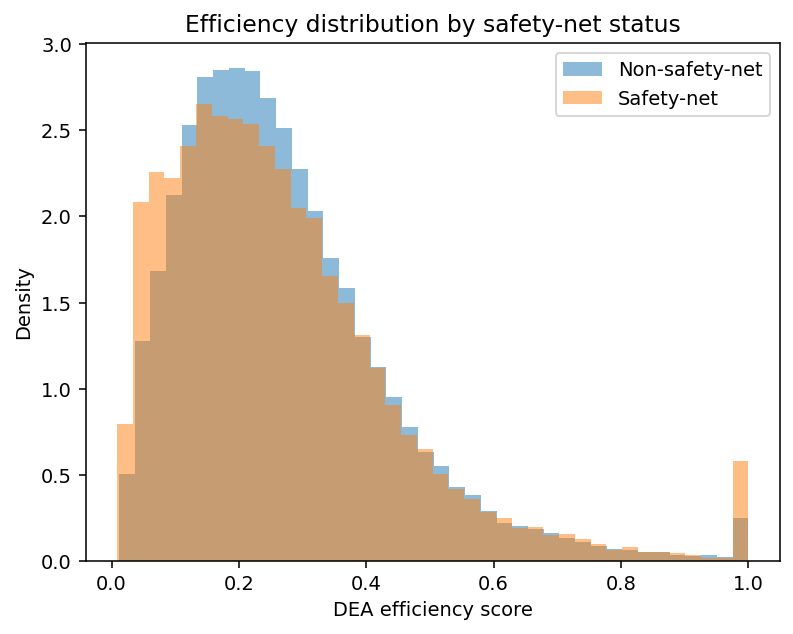

In [44]:
d = eff_df.copy()
d["safety_net"] = d["safety_net"].astype(int)

plt.figure()
for s, label in [(0, "Non-safety-net"), (1, "Safety-net")]:
    vals = d.loc[d["safety_net"]==s, "efficiency"].dropna()
    plt.hist(vals, bins=40, alpha=0.5, density=True, label=label)
plt.xlabel("DEA efficiency score")
plt.ylabel("Density")
plt.title("Efficiency distribution by safety-net status")
plt.legend()
plt.show()


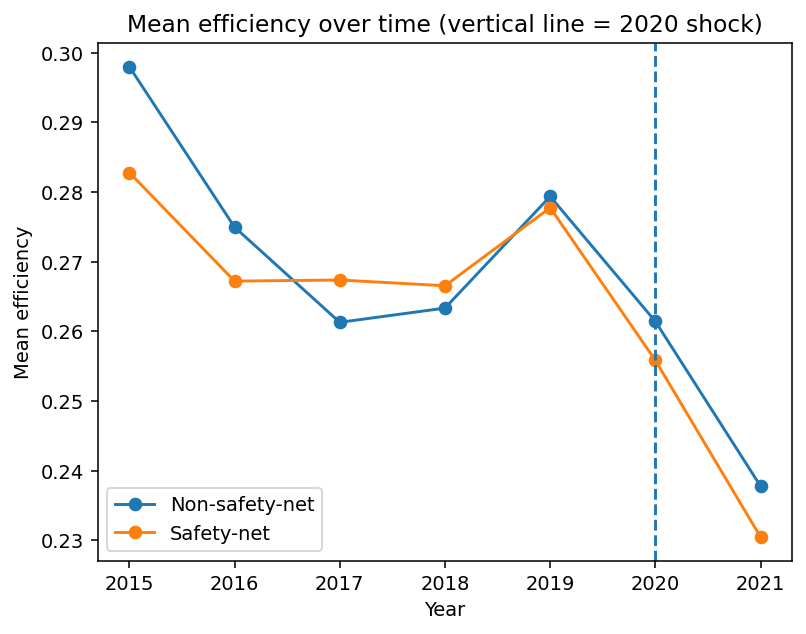

In [45]:
trend = (eff_df.groupby(["year","safety_net"])["efficiency"]
         .mean().reset_index())

plt.figure()
for s, label in [(0, "Non-safety-net"), (1, "Safety-net")]:
    t = trend[trend["safety_net"]==s].sort_values("year")
    plt.plot(t["year"], t["efficiency"], marker="o", label=label)

plt.axvline(2020, linestyle="--")
plt.xlabel("Year")
plt.ylabel("Mean efficiency")
plt.title("Mean efficiency over time (vertical line = 2020 shock)")
plt.legend()
plt.show()


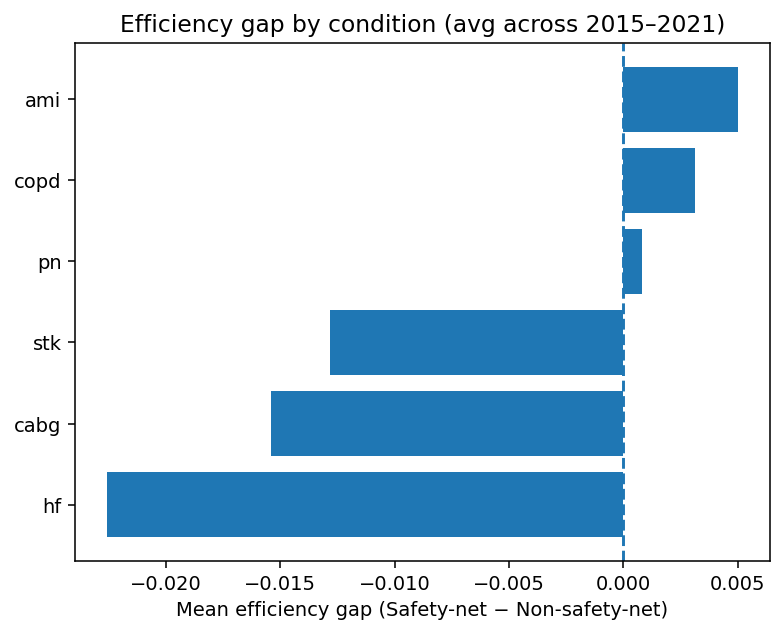

In [46]:
cond = (eff_df.groupby(["condition","safety_net"])["efficiency"]
        .mean().reset_index())

pivot = cond.pivot(index="condition", columns="safety_net", values="efficiency").rename(columns={0:"nonSN", 1:"SN"})
pivot["gap_SN_minus_nonSN"] = pivot["SN"] - pivot["nonSN"]
pivot = pivot.sort_values("gap_SN_minus_nonSN")

plt.figure()
plt.barh(pivot.index, pivot["gap_SN_minus_nonSN"])
plt.axvline(0, linestyle="--")
plt.xlabel("Mean efficiency gap (Safety-net − Non-safety-net)")
plt.title("Efficiency gap by condition (avg across 2015–2021)")
plt.show()


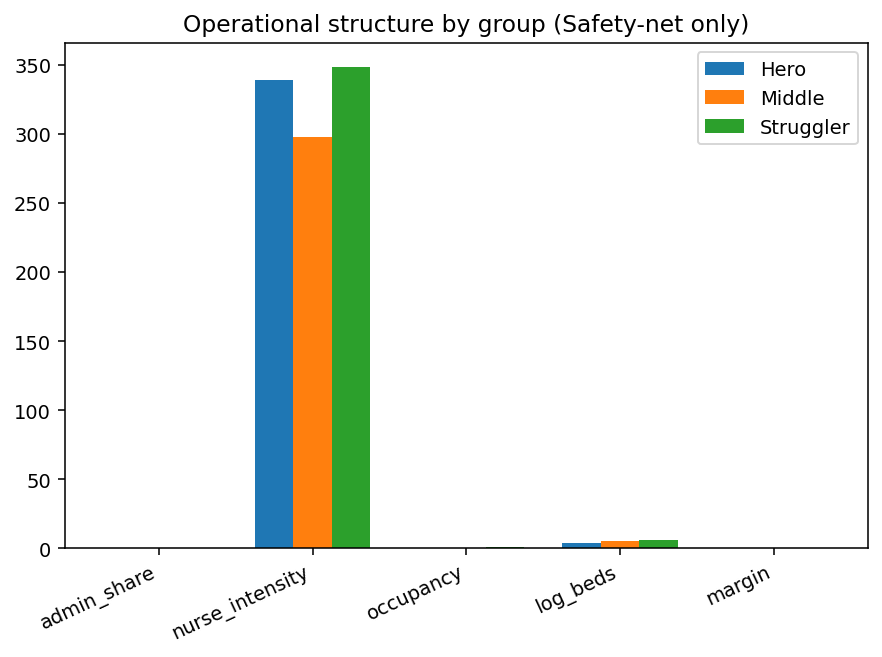

In [48]:
# You already computed group means; reuse sn_reg with 'group' column
features = ["admin_share","nurse_intensity","occupancy","log_beds","margin"]

g = sn_reg.dropna(subset=["group"] + features).groupby("group")[features].mean()
g = g.reindex(["hero","middle","struggler"])

plt.figure()
x = np.arange(len(features))
w = 0.25

plt.bar(x - w, g.loc["hero"], width=w, label="Hero")
plt.bar(x,      g.loc["middle"], width=w, label="Middle")
plt.bar(x + w, g.loc["struggler"], width=w, label="Struggler")

plt.xticks(x, features, rotation=25, ha="right")
plt.title("Operational structure by group (Safety-net only)")
plt.legend()
plt.tight_layout()
plt.show()


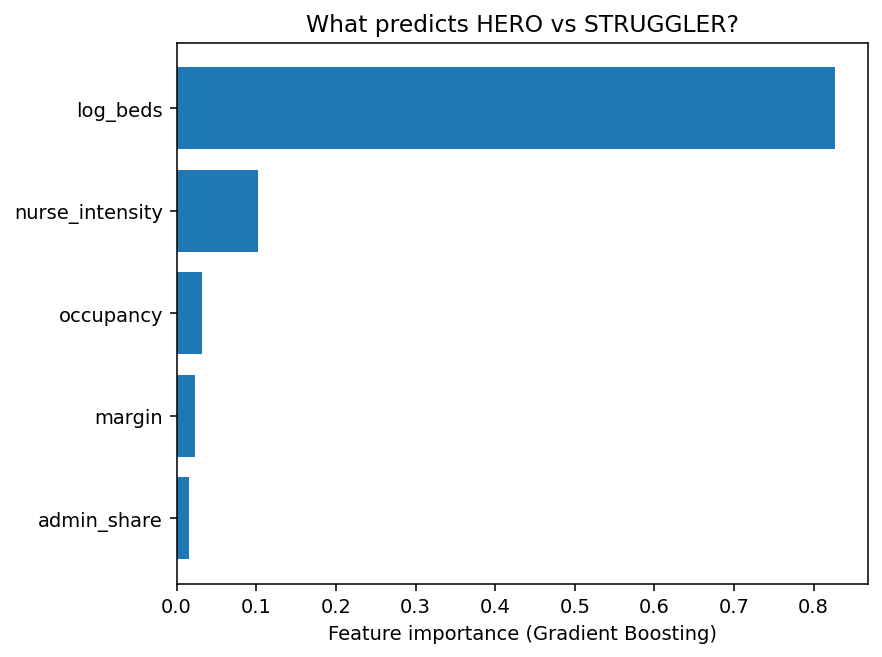

In [49]:
# If you still have clf and X columns:
importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values()

plt.figure()
plt.barh(importances.index, importances.values)
plt.xlabel("Feature importance (Gradient Boosting)")
plt.title("What predicts HERO vs STRUGGLER?")
plt.tight_layout()
plt.show()


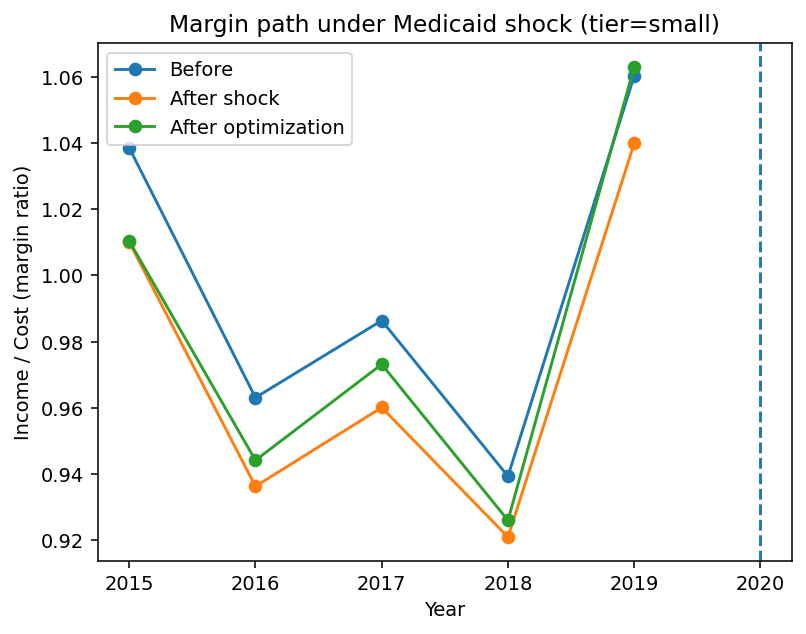

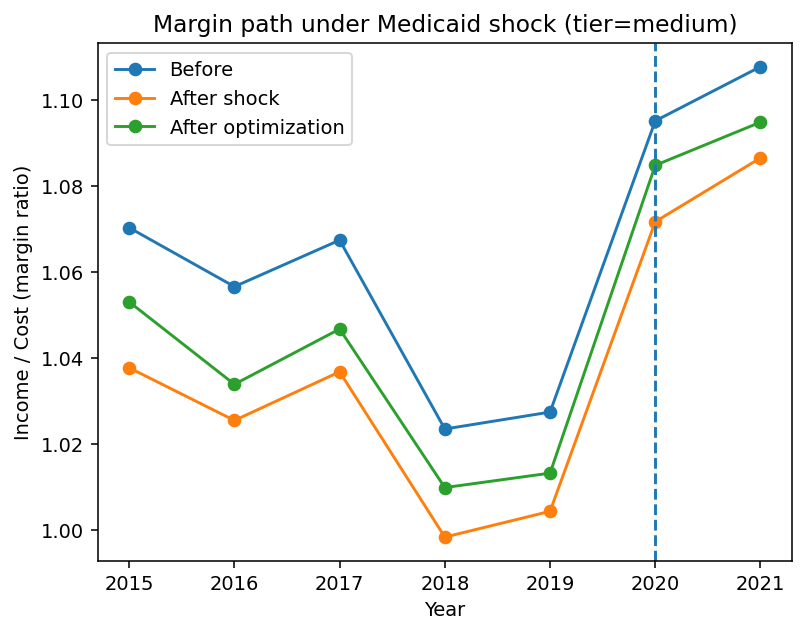

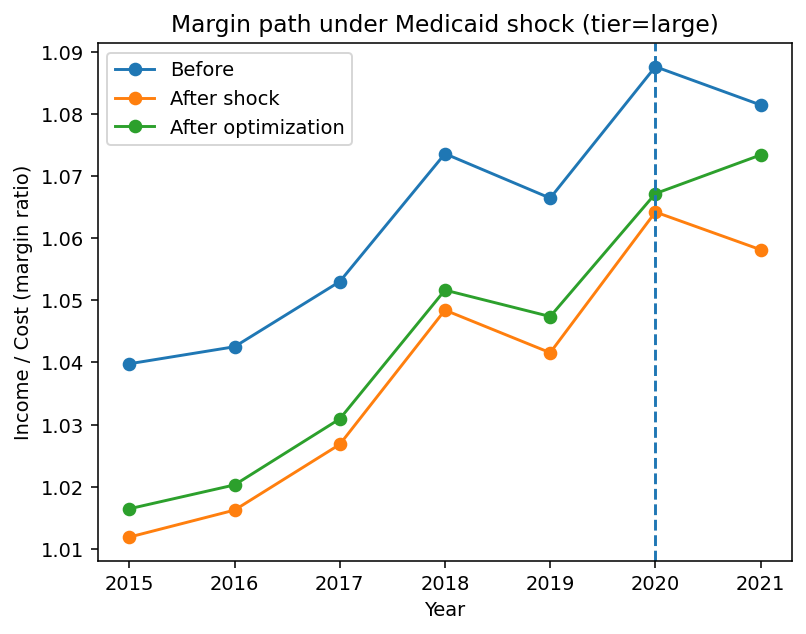

In [50]:
tm = tier_margin.copy().sort_values(["year","size_tier"])

for tier in tm["size_tier"].dropna().unique():
    sub = tm[tm["size_tier"]==tier].sort_values("year")
    plt.figure()
    plt.plot(sub["year"], sub["avg_margin_before"], marker="o", label="Before")
    plt.plot(sub["year"], sub["avg_margin_after_shock"], marker="o", label="After shock")
    plt.plot(sub["year"], sub["avg_margin_after_opt"], marker="o", label="After optimization")
    plt.axvline(2020, linestyle="--")
    plt.title(f"Margin path under Medicaid shock (tier={tier})")
    plt.xlabel("Year")
    plt.ylabel("Income / Cost (margin ratio)")
    plt.legend()
    plt.show()


In [1]:
# Pick the hospital-year with largest rev_loss, or manually choose a prov_num/year
ex = shock.sort_values("rev_loss", ascending=False).head(1).iloc[0]

labels = ["Baseline income", "− Revenue loss", "+ Net savings", "Post-opt income"]
vals = [
    ex["income"],
    -ex["rev_loss"],
    ex["net_savings"],
    ex["income_shocked_opt"]
]

# Waterfall drawing
plt.figure()
running = 0
xs = np.arange(len(labels))
bars = []
for i, v in enumerate(vals[:-1]):
    plt.bar(i, v, bottom=running)
    running += v
# final bar as level
plt.bar(len(labels)-1, vals[-1])

plt.xticks(xs, labels, rotation=20, ha="right")
plt.ylabel("Dollars")
plt.title(f"Case study: Prov {int(ex['prov_num'])}, {int(ex['year'])}")
plt.tight_layout()
plt.show()


NameError: name 'shock' is not defined